# Random Context Retrieval baseline - Stanford Cars

Notebook này triển khai method thứ 2 trong Table 2 của paper: **Random Context Ret.**

Bản chất method theo paper: tạo candidate pool cố định từ train split, sau đó ghép mỗi query image với một context image được chọn ngẫu nhiên từ candidate pool. Retriever không dùng DINO similarity và không học policy.

Notebook này giữ lại phần training/model/checkpoint mạnh từ bản Frozen DINO tốt nhất của bạn: DINOv3 ViT-S/16, token-level query-context fusion, gated query/context head, checkpoint sau từng epoch và cell tính `test_accuracy`. Các phần không đúng bản chất Random Context như DINO nearest-neighbor retrieval và context-label prior được tắt/thay bằng random pairing.


In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !unzip -q /content/drive/MyDrive/archive\ \(13\).zip -d /content/archive\ \(13\)/

## 1. Cài thư viện

Chạy cell này trên Colab nếu môi trường chưa có đủ thư viện. Nếu chạy local đã cài sẵn thì có thể bỏ qua.


In [3]:
%pip -q install torch torchvision pandas pillow tqdm matplotlib torchmetrics


Note: you may need to restart the kernel to use updated packages.


In [4]:
# !wget -c 'https://dinov3.llamameta.net/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth?Policy=eyJTdGF0ZW1lbnQiOlt7InVuaXF1ZV9oYXNoIjoiNTFma3Jxa3l3bTl3MGpweHI2NndvNWZsIiwiUmVzb3VyY2UiOiJodHRwczpcL1wvZGlub3YzLmxsYW1hbWV0YS5uZXRcLyoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkFXUzpFcG9jaFRpbWUiOjE3ODkyOTc0MTJ9fX1dfQ__&Signature=sdowk%7EiiF6j8599sB9K5-M3sB%7Elq1be-oKP%7El7VBISEmjHEBPyCWw9Y2JD4oJY9LbXE313Q4ZgjX%7EXO3EiwGQZ3MZhfkZr0OXmADX8L%7E7XX%7E4mkVA1JSOkVzEa3Oj39gY%7E%7ER21%7EmJXEcFOZPMj%7EzGs-uxIh1xeRrfo-ZUqv3Yz7z7vUgn1OoDhu98kPnh8KT4MF1Gd6gcB4LogqWk3ooVScR6z8ECw50eawfY8lyUUzv%7E%7Em1QdstSU1k6HFhKFbuuogf0MyH7rzYScskxtGG95ke47CKn6CWSNbHLKhcLDfNx-XrN0A-xxis10rpJaMh2jBmxwohSr8XQlGVCBPWqQ__&Key-Pair-Id=K15QRJLYKIFSLZ&Download-Request-ID=1749739516259745' \
#   -O /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth

## 2. Import, cấu hình, dataset và candidate pool

Cell này đọc standard train/test split từ Stanford Cars. Theo protocol paper, candidate pool lấy từ **20% train split** và được giữ cố định. Với Random Context Ret., mỗi query được ghép với context ngẫu nhiên từ pool này; không dùng DINO similarity để xếp hạng.


In [5]:
import json
import random
import subprocess
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm
torch.backends.cudnn.benchmark = True
# Tận dụng Tensor Cores thế hệ mới trên dòng RTX 6000:
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)

from pathlib import Path

# --- ĐƯỜNG DẪN OUTPUT (Ghi vào working của Kaggle) ---
PROJECT_DIR = Path('/kaggle/working')
OUT_PUT_DIR = PROJECT_DIR / 'outputs' / 'baseline_random_context_ret_cars'
OUTPUT_DIR = OUT_PUT_DIR
OUT_PUT_DIR.mkdir(parents=True, exist_ok=True)

# --- ĐƯỜNG DẪN DATASET (Stanford Cars) ---
DATASET_ROOT = Path(
    '/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder'
)
TRAIN_IMAGE_ROOT = DATASET_ROOT / 'car_data' / 'car_data' / 'train'
TEST_IMAGE_ROOT = DATASET_ROOT / 'car_data' / 'car_data' / 'test'

# --- ĐƯỜNG DẪN DINOv3 REPO & WEIGHTS (Chỉ trỏ tới thư mục chứa hubconf.py) ---
DINOV3_REPO_DIR = (
    '/kaggle/input/datasets/sinhnguync/dinov3-code/dinov3-main'  # thư mục chứa hubconf.py
)
DINOV3_MODEL_NAME = 'dinov3_vits16'
DINOV3_WEIGHTS = '/kaggle/input/datasets/sinhnguync/dinov3/dinov3_vits16_pretrain_lvd1689m-08c60483.pth'

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 384

IMAGE_SIZE = 448
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4  # legacy default kept for older cells; optimizer below uses param groups
BACKBONE_LR = 3e-6
HEAD_LR = 1e-4
BACKBONE_WEIGHT_DECAY = 0.05
HEAD_WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
TOKEN_HEAD_DROPOUT = 0.3
FREEZE_BACKBONE_EPOCHS = 5
WARMUP_EPOCHS = 5
PATIENCE = 10
GRAD_CLIP_NORM = 1.0
NUM_WORKERS = 8
NUM_CLASSES = 196
TOP_K = 5
CONTEXT_TOP_K = 1
RETRIEVAL_SCORE_WEIGHT = 0.0
SUPCON_WEIGHT = 0.05
SUPCON_TEMPERATURE = 0.10
USE_BBOX_CROP = True
CANDIDATE_POOL_FRACTION = 0.20
VAL_FRACTION = 0.10
RETRIEVAL_BATCH_SIZE = 512
RETRIEVAL_CHUNK_SIZE = 4096
QUERY_CONTEXT_GATE_DROPOUT = 0.20
QUERY_CONTEXT_GATE_BIAS = -0.7
EVAL_TTA_HORIZONTAL_FLIP = True
USE_CONTEXT_LABEL_PRIOR = False
CONTEXT_LABEL_PRIOR_WEIGHT = 0.25
CONTEXT_LABEL_PRIOR_TEMPERATURE = 0.07

TRAIN_ON_FULL_TRAIN = True
FULL_TRAIN_MONITOR_FRACTION = 0.05
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 48, IMAGE_SIZE + 48)),
    transforms.RandomResizedCrop(
        (IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.60, 1.0),
        ratio=(0.80, 1.25),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.25,
            contrast=0.25,
            saturation=0.20,
            hue=0.04,
        )
    ], p=0.75),
    transforms.RandomGrayscale(p=0.05),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.15),
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.20,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3),
        value="random",
    ),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
# Deterministic transform for validation / test / candidate feature extraction
# Không dùng augmentation mạnh ở eval/retrieval để tránh retrieval bị nhiễu.

_mean = globals().get("DINO_MEAN", globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))
_std = globals().get("DINO_STD", globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=_mean, std=_std),
])

def load_class_names(dataset_root):
    class_names = pd.read_csv(dataset_root / 'names.csv', header=None)[0].astype(str).tolist()
    if len(class_names) != NUM_CLASSES:
        raise ValueError(f'Expected {NUM_CLASSES} classes, got {len(class_names)}')
    return class_names


def load_annotations(dataset_root, split):
    df = pd.read_csv(
        dataset_root / f'anno_{split}.csv',
        header=None,
        names=['fname', 'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'class_id_1based'],
    )
    df['class_id'] = df['class_id_1based'].astype(int) - 1
    df['split'] = split
    df['row_id'] = np.arange(len(df))
    return df


def attach_image_paths(df, image_root):
    image_index = {path.name: path for path in sorted(Path(image_root).rglob('*.jpg'))}
    missing = [fname for fname in df['fname'] if fname not in image_index]
    if missing:
        raise FileNotFoundError(f'Thieu anh trong {image_root}, vi du: {missing[:5]}')
    out = df.copy()
    out['image_path'] = [str(image_index[fname]) for fname in out['fname']]
    return out


def split_train_val_by_class(df, val_fraction=0.10, seed=42):
    if not 0 < val_fraction < 1:
        raise ValueError('val_fraction phải nằm trong khoảng (0, 1)')
    rng = np.random.default_rng(seed)
    val_indices = []
    for _, group in df.groupby('class_id', sort=True):
        group_indices = group.index.to_numpy()
        if len(group_indices) <= 1:
            continue
        n_val = max(1, int(round(len(group_indices) * val_fraction)))
        n_val = min(n_val, len(group_indices) - 1)
        val_indices.extend(rng.choice(group_indices, size=n_val, replace=False).tolist())
    val_indices = np.array(sorted(val_indices), dtype=int)
    train_split = df.drop(index=val_indices).reset_index(drop=True)
    val_split = df.loc[val_indices].reset_index(drop=True)
    return train_split, val_split


class_names = load_class_names(DATASET_ROOT)
full_train_df = attach_image_paths(load_annotations(DATASET_ROOT, 'train'), TRAIN_IMAGE_ROOT).reset_index(drop=True)
test_df = attach_image_paths(load_annotations(DATASET_ROOT, 'test'), TEST_IMAGE_ROOT).reset_index(drop=True)
train_df, val_df = split_train_val_by_class(full_train_df, VAL_FRACTION, SEED)
NUM_CLASSES = len(class_names)
if TRAIN_ON_FULL_TRAIN:
    _, monitor_val_df = split_train_val_by_class(
        full_train_df,
        FULL_TRAIN_MONITOR_FRACTION,
        SEED
    )
    train_df = full_train_df.reset_index(drop=True)
    val_df = monitor_val_df.reset_index(drop=True)

candidate_rng = np.random.default_rng(SEED)
if CANDIDATE_POOL_FRACTION >= 1.0:
    candidate_pool_positions = np.arange(len(train_df), dtype=int)
else:
    candidate_pool_size = max(1, int(round(len(train_df) * CANDIDATE_POOL_FRACTION)))
    candidate_pool_positions = np.sort(candidate_rng.choice(len(train_df), size=candidate_pool_size, replace=False))
candidate_df = train_df.iloc[candidate_pool_positions].reset_index(drop=True)
candidate_df.to_csv(OUT_PUT_DIR / 'candidate_pool.csv', index=False)
val_df.to_csv(OUT_PUT_DIR / 'validation_split.csv', index=False)

print('DATASET_ROOT:', DATASET_ROOT.resolve())
print('TRAIN_IMAGE_ROOT:', TRAIN_IMAGE_ROOT.resolve())
print('TEST_IMAGE_ROOT:', TEST_IMAGE_ROOT.resolve())
print('OUT_PUT_DIR:', OUT_PUT_DIR.resolve())
print(f'Standard train images: {len(full_train_df):,}')
print(f'Actual train images: {len(train_df):,}')
print(f'Monitor validation images: {len(val_df):,}')
print(f'Train on full train: {TRAIN_ON_FULL_TRAIN}')
print(f'Standard test images: {len(test_df):,}')
print(f'Candidate pool: {len(candidate_df):,}/{len(train_df):,} actual-train images ({CANDIDATE_POOL_FRACTION:.0%})')
print(f'Random context(s) per query: {CONTEXT_TOP_K}')
print(f'BBox crop enabled: {USE_BBOX_CROP}')
print(f'Train label range: {int(train_df.class_id.min())}..{int(train_df.class_id.max())}')
print(f'Test label range: {int(test_df.class_id.min())}..{int(test_df.class_id.max())}')
display(train_df.head())
display(val_df.head())
display(candidate_df.head())


DEVICE: cuda
DATASET_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder
TRAIN_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/train
TEST_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/test
OUT_PUT_DIR: /kaggle/working/outputs/baseline_random_context_ret_cars
Standard train images: 8,144
Actual train images: 8,144
Monitor validation images: 390
Train on full train: True
Standard test images: 8,041
Candidate pool: 1,629/8,144 actual-train images (20%)
Random context(s) per query: 1
BBox crop enabled: True
Train label range: 0..195
Test label range: 0..195


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00001.jpg,39,116,569,375,14,13,train,0,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00002.jpg,36,116,868,587,3,2,train,1,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00003.jpg,85,109,601,381,91,90,train,2,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00004.jpg,621,393,1484,1096,134,133,train,3,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00005.jpg,14,36,133,99,106,105,train,4,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00003.jpg,85,109,601,381,91,90,train,2,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00020.jpg,17,281,961,596,57,56,train,19,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00063.jpg,175,330,928,647,101,100,train,62,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00079.jpg,165,126,749,425,133,132,train,78,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00092.jpg,101,84,492,272,138,137,train,91,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00010.jpg,21,110,623,367,58,57,train,9,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00013.jpg,30,36,418,307,135,134,train,12,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00014.jpg,31,246,778,540,85,84,train,13,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00033.jpg,34,197,1011,656,66,65,train,32,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00036.jpg,138,41,521,223,104,103,train,35,/kaggle/input/datasets/jutrera/stanford-car-da...


## 3. Dataset pair và DataLoader

Mỗi sample trả về `(query_image, context_images, label, query_fname, context_fnames, context_labels, context_scores)`. Với Random Context Ret., context đã được sample cố định bằng seed từ candidate pool.


In [6]:
class SimpleImageDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = crop_bbox

    def __len__(self):
        return len(self.annotations)

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        image = self.transform(self._open_image(row))
        return image, int(index), row['fname'], int(row['class_id'])


class StanfordCarsSimilarityContextDataset(Dataset):
    def __init__(self, annotations, candidate_annotations, context_positions, context_scores, query_transform, context_transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.candidate_annotations = candidate_annotations.reset_index(drop=True).copy()
        self.context_positions = np.asarray(context_positions, dtype=np.int64)
        self.context_scores = np.asarray(context_scores, dtype=np.float32)
        if self.context_positions.ndim == 1:
            self.context_positions = self.context_positions[:, None]
        if self.context_scores.ndim == 1:
            self.context_scores = self.context_scores[:, None]
        self.query_transform = query_transform
        self.context_transform = context_transform
        self.crop_bbox = crop_bbox
        if len(self.context_positions) != len(self.annotations):
            raise ValueError('context_positions phai co cung do dai voi annotations')
        if len(self.context_scores) != len(self.annotations):
            raise ValueError('context_scores phai co cung do dai voi annotations')

    def __len__(self):
        return len(self.annotations)

    def set_epoch(self, epoch):
        pass

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        query_row = self.annotations.iloc[index]
        context_positions = self.context_positions[index]
        context_scores = self.context_scores[index]
        context_rows = [self.candidate_annotations.iloc[int(pos)] for pos in context_positions]
        query_image = self.query_transform(self._open_image(query_row))
        context_images = torch.stack([self.context_transform(self._open_image(context_row)) for context_row in context_rows], dim=0)
        context_labels = torch.tensor([int(context_row['class_id']) for context_row in context_rows], dtype=torch.long)
        return {
            'query_image': query_image,
            'context_images': context_images,
            'label': torch.tensor(int(query_row['class_id']), dtype=torch.long),
            'fname': query_row['fname'],
            'context_fnames': '|'.join(str(context_row['fname']) for context_row in context_rows),
            "context_labels": torch.tensor(context_labels, dtype=torch.long),
            'context_scores': torch.as_tensor(context_scores, dtype=torch.float32),
        }


## 4. Random context retrieval và downstream model

Retriever: không dùng DINO similarity. Với mỗi query, notebook sample ngẫu nhiên `CONTEXT_TOP_K` context từ candidate pool cố định. Điểm retrieval đặt bằng 0 vì random retrieval không có similarity score.

Downstream classifier: giữ kiến trúc mạnh từ notebook tốt nhất: DINOv3 ViT-S/16, token-level query-context fusion và gated query/context head. Khi `CONTEXT_TOP_K = 1`, kiến trúc này tương ứng với việc train trên một cặp `(query image, random context image)`.


In [7]:
from pathlib import Path
import gc
import torch


def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {path}')
    return str(path)


def load_dinov3_model(repo_dir, model_name, weights_path):
    repo_dir = Path(repo_dir)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {weights_path}')
    return torch.hub.load(str(repo_dir), model_name, source='local', weights=str(weights_path))


def load_dinov3_backbone():
    return load_dinov3_model(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights())


def ensure_dinov3_assets():
    resolve_dinov3_weights()
    repo_dir = Path(DINOV3_REPO_DIR)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    print('DINOv3 assets đã sẵn sàng từ Kaggle Input.')




class DinoV3RandomContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=384, allow_feature_fallback=False):
        super().__init__()
        self.backbone = load_dinov3_model(repo_dir, model_name, weights_path)
        self.feature_dim = feature_dim
        self.allow_feature_fallback = allow_feature_fallback
        self.active_fusion_mode = 'topk_token_attention'
        self.context_proj = nn.Linear(feature_dim, feature_dim)
        self.query_proj = nn.Linear(feature_dim, feature_dim)
        self.context_attention = nn.Linear(feature_dim, 1)
        self.fusion_norm = nn.LayerNorm(feature_dim)
        self.token_head = nn.Sequential(nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        self.feature_fusion = nn.Sequential(nn.Linear(feature_dim * 2, feature_dim), nn.GELU(), nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        for param in self.backbone.parameters():
            param.requires_grad_(False)

    def _prefix_token_count(self):
        if hasattr(self.backbone, 'num_prefix_tokens'):
            return int(self.backbone.num_prefix_tokens)
        storage_tokens = getattr(self.backbone, 'n_storage_tokens', None)
        if storage_tokens is None:
            storage_tokens = getattr(self.backbone, 'num_register_tokens', 0)
        return 1 + int(storage_tokens or 0)

    def _patch_grid(self, images):
        patch_size = getattr(self.backbone, 'patch_size', 16)
        if isinstance(patch_size, (tuple, list)):
            patch_h, patch_w = int(patch_size[0]), int(patch_size[1])
        else:
            patch_h = patch_w = int(patch_size)
        return images.shape[-2] // patch_h, images.shape[-1] // patch_w

    def _unwrap_tokens(self, prepared):
        if torch.is_tensor(prepared):
            return prepared
        if isinstance(prepared, (tuple, list)):
            for item in prepared:
                if torch.is_tensor(item):
                    return item
        if isinstance(prepared, dict):
            for key in ('x', 'tokens', 'last_hidden_state'):
                if key in prepared and torch.is_tensor(prepared[key]):
                    return prepared[key]
            for item in prepared.values():
                if torch.is_tensor(item):
                    return item
        raise TypeError(f'Cannot unwrap DINO token output of type {type(prepared)}')

    def _prepare_tokens_with_rope(self, images):
        try:
            prepared = self.backbone.prepare_tokens_with_masks(images, None)
        except TypeError:
            prepared = self.backbone.prepare_tokens_with_masks(images)
        tokens = self._unwrap_tokens(prepared)
        rope = None
        if hasattr(self.backbone, 'rope_embed'):
            grid_h, grid_w = self._patch_grid(images)
            try:
                rope = self.backbone.rope_embed(H=grid_h, W=grid_w)
            except TypeError:
                rope = self.backbone.rope_embed(grid_h, grid_w)
        return tokens, rope

    def _repeat_rope_for_query_context(self, rope):
        if rope is None or not torch.is_tensor(rope):
            return rope
        try:
            return rope.repeat_interleave(2, dim=-2)
        except RuntimeError:
            return rope

    def _run_blocks(self, tokens, rope):
        for block in self.backbone.blocks:
            if rope is None:
                tokens = block(tokens)
                continue
            try:
                tokens = block(tokens, rope=rope)
            except TypeError:
                try:
                    tokens = block(tokens, rope)
                except TypeError:
                    tokens = block(tokens)
        if hasattr(self.backbone, 'norm'):
            tokens = self.backbone.norm(tokens)
        return tokens

    def _forward_token_concat_features(self, query_images, context_images):
        query_tokens, query_rope = self._prepare_tokens_with_rope(query_images)
        context_tokens, _ = self._prepare_tokens_with_rope(context_images)
        prefix_tokens = self._prefix_token_count()
        pair_tokens = torch.cat([query_tokens[:, :prefix_tokens], query_tokens[:, prefix_tokens:], context_tokens[:, prefix_tokens:]], dim=1)
        pair_rope = self._repeat_rope_for_query_context(query_rope)
        pair_tokens = self._run_blocks(pair_tokens, pair_rope)
        return pair_tokens[:, 0]

    def _pool_backbone_features(self, images):
        features = self.backbone.forward_features(images)
        if isinstance(features, dict):
            if 'x_norm_clstoken' in features:
                return features['x_norm_clstoken']
            if 'x_norm_patchtokens' in features:
                return features['x_norm_patchtokens'].mean(dim=1)
            for item in features.values():
                if torch.is_tensor(item):
                    return item[:, 0] if item.ndim == 3 else item
        if torch.is_tensor(features):
            return features[:, 0] if features.ndim == 3 else features
        raise TypeError(f'Cannot pool DINO features of type {type(features)}')

    def _forward_feature_fusion(self, query_images, context_images):
        if context_images.ndim == 5:
            context_images = context_images[:, 0]
        query_features = self._pool_backbone_features(query_images)
        context_features = self._pool_backbone_features(context_images)
        self.active_fusion_mode = 'feature_fusion'
        return self.feature_fusion(torch.cat([query_features, context_features], dim=1))

    def _forward_topk_token_attention(self, query_images, context_images, context_scores=None):
        if context_images.ndim == 4:
            context_images = context_images.unsqueeze(1)
        batch_size, num_contexts, channels, height, width = context_images.shape
        query_repeated = query_images.unsqueeze(1).expand(-1, num_contexts, -1, -1, -1).reshape(batch_size * num_contexts, channels, height, width)
        context_flat = context_images.reshape(batch_size * num_contexts, channels, height, width)
        pair_features = self._forward_token_concat_features(query_repeated, context_flat).reshape(batch_size, num_contexts, self.feature_dim)
        query_summary = pair_features.mean(dim=1)
        attention_hidden = torch.tanh(self.context_proj(pair_features) + self.query_proj(query_summary).unsqueeze(1))
        attention_logits = self.context_attention(attention_hidden).squeeze(-1)
        if context_scores is not None:
            if context_scores.ndim == 1:
                context_scores = context_scores.unsqueeze(1)
            attention_logits = attention_logits + RETRIEVAL_SCORE_WEIGHT * context_scores.to(attention_logits.device, dtype=attention_logits.dtype)
        attention_weights = torch.softmax(attention_logits, dim=1)
        fused_features = torch.sum(pair_features * attention_weights.unsqueeze(-1), dim=1)
        fused_features = self.fusion_norm(fused_features)
        self.active_fusion_mode = 'topk_token_attention'
        return fused_features, attention_weights

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            fused_features, attention_weights = self._forward_topk_token_attention(query_images, context_images, context_scores=context_scores)
            logits = self.token_head(fused_features)
            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits
        except Exception as exc:
            if self.allow_feature_fallback:
                print(f'Top-k token attention failed, fallback to feature fusion: {type(exc).__name__}: {exc}')
                logits = self._forward_feature_fusion(query_images, context_images)
                if return_features:
                    return logits, F.normalize(logits.float(), dim=1), None
                return logits
            raise RuntimeError('Top-k token attention failed. Keep allow_feature_fallback=False for debugging.') from exc

class DinoV3GatedTopKContextClassifier(DinoV3RandomContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=384, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.query_norm = nn.LayerNorm(feature_dim)
        self.context_norm = nn.LayerNorm(feature_dim)
        self.final_norm = nn.LayerNorm(feature_dim)

        self.query_head = nn.Sequential(
            nn.Dropout(p=TOKEN_HEAD_DROPOUT),
            nn.Linear(feature_dim, num_classes),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(feature_dim * 4, feature_dim),
            nn.GELU(),
            nn.Dropout(p=QUERY_CONTEXT_GATE_DROPOUT),
            nn.Linear(feature_dim, 1),
        )
        nn.init.constant_(self.fusion_gate[-1].bias, QUERY_CONTEXT_GATE_BIAS)
        self.active_fusion_mode = "query_plus_gated_topk_context"

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            context_features, attention_weights = self._forward_topk_token_attention(
                query_images,
                context_images,
                context_scores=context_scores,
            )
            query_features = self._pool_backbone_features(query_images)

            query_features = self.query_norm(query_features)
            context_features = self.context_norm(context_features)

            gate_input = torch.cat(
                [
                    query_features,
                    context_features,
                    query_features * context_features,
                    torch.abs(query_features - context_features),
                ],
                dim=1,
            )
            gate = torch.sigmoid(self.fusion_gate(gate_input))

            query_logits = self.query_head(query_features)
            context_logits = self.token_head(context_features)
            logits = query_logits + gate * context_logits

            fused_features = self.final_norm(query_features + gate * context_features)
            self.active_fusion_mode = "query_plus_gated_topk_context"

            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits

        except Exception as exc:
            if self.allow_feature_fallback:
                print(f"Gated fusion failed, fallback to parent model: {type(exc).__name__}: {exc}")
                return super().forward(query_images, context_images, context_scores=context_scores, return_features=return_features)
            raise
def sample_random_contexts(query_df, candidate_df, top_k=1, seed=SEED, exclude_self=False):
    """Sample fixed random context positions for every query.

    This is the Random Context Ret. baseline: no DINO similarity and no learned selector.
    The returned scores are zeros so the downstream model receives no retrieval ranking signal.
    """
    rng = np.random.default_rng(seed)
    top_k = int(max(1, min(top_k, len(candidate_df))))
    all_positions = np.arange(len(candidate_df), dtype=np.int64)
    candidate_row_id_to_position = {
        int(row_id): pos for pos, row_id in enumerate(candidate_df['row_id'].tolist())
    }
    positions = np.empty((len(query_df), top_k), dtype=np.int64)
    scores = np.zeros((len(query_df), top_k), dtype=np.float32)

    for query_index in range(len(query_df)):
        valid_positions = all_positions
        if exclude_self:
            query_row_id = int(query_df.iloc[query_index]['row_id'])
            self_position = candidate_row_id_to_position.get(query_row_id)
            if self_position is not None and len(all_positions) > 1:
                valid_positions = all_positions[all_positions != self_position]
        replace = len(valid_positions) < top_k
        positions[query_index] = rng.choice(valid_positions, size=top_k, replace=replace)

    return positions, scores


def build_random_pairs_df(query_df, candidate_df, context_positions, context_scores):
    context_positions = np.asarray(context_positions)
    context_scores = np.asarray(context_scores)
    if context_positions.ndim == 1:
        context_positions = context_positions[:, None]
        context_scores = context_scores[:, None]

    rows = []
    for query_pos, (positions_row, scores_row) in enumerate(zip(context_positions, context_scores)):
        query = query_df.iloc[query_pos]
        contexts = [candidate_df.iloc[int(pos)] for pos in positions_row]
        query_class_id = int(query['class_id'])
        context_class_ids = [int(context['class_id']) for context in contexts]
        rows.append({
            'query_fname': query['fname'],
            'query_class_id': query_class_id,
            'query_car_name': class_names[query_class_id],
            'top1_context_fname': contexts[0]['fname'],
            'top1_context_class_id': context_class_ids[0],
            'top1_context_car_name': class_names[context_class_ids[0]],
            'top1_context_pool_position': int(positions_row[0]),
            'top1_context_train_row_id': int(contexts[0]['row_id']),
            'top1_random_score': float(scores_row[0]),
            'context_fnames': '|'.join(str(context['fname']) for context in contexts),
            'context_class_ids': '|'.join(str(class_id) for class_id in context_class_ids),
            'context_pool_positions': '|'.join(str(int(pos)) for pos in positions_row),
            'random_scores': '|'.join(f'{float(score):.6f}' for score in scores_row),
            'same_class': bool(query_class_id == context_class_ids[0]),
            'same_class_top1': bool(query_class_id == context_class_ids[0]),
            'same_class_any_topk': bool(query_class_id in context_class_ids),
        })
    return pd.DataFrame(rows)


ensure_dinov3_assets()

train_context_positions, train_context_scores = sample_random_contexts(
    train_df,
    candidate_df,
    top_k=CONTEXT_TOP_K,
    seed=SEED + 101,
    exclude_self=True,
)
val_context_positions, val_context_scores = sample_random_contexts(
    val_df,
    candidate_df,
    top_k=CONTEXT_TOP_K,
    seed=SEED + 202,
    exclude_self=False,
)
test_context_positions, test_context_scores = sample_random_contexts(
    test_df,
    candidate_df,
    top_k=CONTEXT_TOP_K,
    seed=SEED + 303,
    exclude_self=False,
)

train_random_pairs_df = build_random_pairs_df(train_df, candidate_df, train_context_positions, train_context_scores)
val_random_pairs_df = build_random_pairs_df(val_df, candidate_df, val_context_positions, val_context_scores)
test_random_pairs_df = build_random_pairs_df(test_df, candidate_df, test_context_positions, test_context_scores)

train_random_pairs_df.to_csv(OUT_PUT_DIR / 'train_random_context_pairs.csv', index=False)
val_random_pairs_df.to_csv(OUT_PUT_DIR / 'val_random_context_pairs.csv', index=False)
test_random_pairs_df.to_csv(OUT_PUT_DIR / 'test_random_context_pairs.csv', index=False)

train_top1_same_class_context_rate = float(train_random_pairs_df['same_class_top1'].mean())
val_top1_same_class_context_rate = float(val_random_pairs_df['same_class_top1'].mean())
test_top1_same_class_context_rate = float(test_random_pairs_df['same_class_top1'].mean())
train_same_class_context_rate = float(train_random_pairs_df['same_class_any_topk'].mean())
val_same_class_context_rate = float(val_random_pairs_df['same_class_any_topk'].mean())
test_same_class_context_rate = float(test_random_pairs_df['same_class_any_topk'].mean())

torch.save({
    'candidate_pool_positions': torch.as_tensor(candidate_pool_positions, dtype=torch.long),
    'train_context_positions': torch.as_tensor(train_context_positions, dtype=torch.long),
    'train_context_scores': torch.as_tensor(train_context_scores, dtype=torch.float32),
    'val_context_positions': torch.as_tensor(val_context_positions, dtype=torch.long),
    'val_context_scores': torch.as_tensor(val_context_scores, dtype=torch.float32),
    'test_context_positions': torch.as_tensor(test_context_positions, dtype=torch.long),
    'test_context_scores': torch.as_tensor(test_context_scores, dtype=torch.float32),
    'seed': SEED,
    'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
    'context_top_k': CONTEXT_TOP_K,
    'use_bbox_crop': USE_BBOX_CROP,
    'method': 'random_context_retrieval',
}, OUT_PUT_DIR / 'random_context_retrieval_cache.pt')

train_dataset = StanfordCarsSimilarityContextDataset(
    train_df,
    candidate_df,
    train_context_positions,
    train_context_scores,
    train_transform,
    train_transform,
    crop_bbox=USE_BBOX_CROP,
)
val_dataset = StanfordCarsSimilarityContextDataset(
    val_df,
    candidate_df,
    val_context_positions,
    val_context_scores,
    eval_transform,
    eval_transform,
    crop_bbox=USE_BBOX_CROP,
)
test_dataset = StanfordCarsSimilarityContextDataset(
    test_df,
    candidate_df,
    test_context_positions,
    test_context_scores,
    eval_transform,
    eval_transform,
    crop_bbox=USE_BBOX_CROP,
)

loader_kwargs = {'num_workers': NUM_WORKERS, 'pin_memory': torch.cuda.is_available()}
if NUM_WORKERS > 0:
    loader_kwargs['persistent_workers'] = True
    loader_kwargs['prefetch_factor'] = 2

train_generator = torch.Generator()
train_generator.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

model = DinoV3GatedTopKContextClassifier(
    DINOV3_REPO_DIR,
    DINOV3_MODEL_NAME,
    resolve_dinov3_weights(),
    NUM_CLASSES,
    FEATURE_DIM,
    allow_feature_fallback=False,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
backbone_params = [p for name, p in model.named_parameters() if name.startswith('backbone.')]
head_params = [p for name, p in model.named_parameters() if not name.startswith('backbone.')]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': BACKBONE_LR, 'weight_decay': BACKBONE_WEIGHT_DECAY, 'name': 'backbone'},
    {'params': head_params, 'lr': HEAD_LR, 'weight_decay': HEAD_WEIGHT_DECAY, 'name': 'head'},
])

warmup_epochs = max(1, min(WARMUP_EPOCHS, EPOCHS))
main_epochs = max(1, EPOCHS - warmup_epochs)
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.2, end_factor=1.0, total_iters=warmup_epochs)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=main_epochs, eta_min=1e-7)
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_epochs])
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')

checkpoint_path = OUT_PUT_DIR / 'final_random_context_ret_dinov3_vits16_cars.pt'
last_checkpoint_path = OUT_PUT_DIR / 'checkpoint_last.pt'
best_checkpoint_path = OUT_PUT_DIR / 'best_val_checkpoint.pt'

sample = train_dataset[0]
print('Saved random retrieval cache:', (OUT_PUT_DIR / 'random_context_retrieval_cache.pt').resolve())
print('Saved train random pairs:', (OUT_PUT_DIR / 'train_random_context_pairs.csv').resolve())
print('Saved val random pairs:', (OUT_PUT_DIR / 'val_random_context_pairs.csv').resolve())
print('Saved test random pairs:', (OUT_PUT_DIR / 'test_random_context_pairs.csv').resolve())
print('Sample tensors:', sample['query_image'].shape, sample['context_images'].shape)
print('Query random context:', sample['fname'], '->', sample['context_fnames'])
print('Context scores:', sample['context_scores'].tolist())
print(f'Train top1/any-top{CONTEXT_TOP_K} same-class random context rate: {train_top1_same_class_context_rate:.4f} / {train_same_class_context_rate:.4f}')
print(f'Val top1/any-top{CONTEXT_TOP_K} same-class random context rate: {val_top1_same_class_context_rate:.4f} / {val_same_class_context_rate:.4f}')
print(f'Test top1/any-top{CONTEXT_TOP_K} same-class random context rate: {test_top1_same_class_context_rate:.4f} / {test_same_class_context_rate:.4f}')
print('Initial fusion mode:', model.active_fusion_mode)
display(test_random_pairs_df.head())
print(model)


DINOv3 assets đã sẵn sàng từ Kaggle Input.
Downloading: "file:///kaggle/input/datasets/sinhnguync/dinov3/dinov3_vits16_pretrain_lvd1689m-08c60483.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


100%|██████████| 82.5M/82.5M [00:01<00:00, 56.8MB/s]
/tmp/ipykernel_163/1792867779.py:435: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')


Saved random retrieval cache: /kaggle/working/outputs/baseline_random_context_ret_cars/random_context_retrieval_cache.pt
Saved train random pairs: /kaggle/working/outputs/baseline_random_context_ret_cars/train_random_context_pairs.csv
Saved val random pairs: /kaggle/working/outputs/baseline_random_context_ret_cars/val_random_context_pairs.csv
Saved test random pairs: /kaggle/working/outputs/baseline_random_context_ret_cars/test_random_context_pairs.csv
Sample tensors: torch.Size([3, 448, 448]) torch.Size([1, 3, 448, 448])
Query random context: 00001.jpg -> 07544.jpg
Context scores: [0.0]
Train top1/any-top1 same-class random context rate: 0.0041 / 0.0041
Val top1/any-top1 same-class random context rate: 0.0026 / 0.0026
Test top1/any-top1 same-class random context rate: 0.0052 / 0.0052
Initial fusion mode: query_plus_gated_topk_context


/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),


,query_fname,query_class_id,query_car_name,top1_context_fname,top1_context_class_id,top1_context_car_name,top1_context_pool_position,top1_context_train_row_id,top1_random_score,context_fnames,context_class_ids,context_pool_positions,random_scores,same_class,same_class_top1,same_class_any_topk
0,00001.jpg,180,Suzuki Aerio Sedan 2007,02435.jpg,174,Rolls-Royce Phantom Drophead Coupe Convertible...,483,2434,0.0,02435.jpg,174,483,0.000000,False,False,False
1,00002.jpg,102,Ferrari 458 Italia Convertible 2012,05287.jpg,151,Lamborghini Gallardo LP 570-4 Superleggera 2012,1056,5286,0.0,05287.jpg,151,1056,0.000000,False,False,False
2,00003.jpg,144,Jeep Patriot SUV 2012,00764.jpg,164,Mercedes-Benz S-Class Sedan 2012,150,763,0.0,00764.jpg,164,150,0.000000,False,False,False
3,00004.jpg,186,Toyota Camry Sedan 2012,03304.jpg,62,Chevrolet Sonic Sedan 2012,644,3303,0.0,03304.jpg,62,644,0.000000,False,False,False
4,00005.jpg,184,Tesla Model S Sedan 2012,06061.jpg,1,Acura RL Sedan 2012,1205,6060,0.0,06061.jpg,1,1205,0.000000,False,False,False


DinoV3GatedTopKContextClassifier(
  (backbone): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (rope_embed): RopePositionEmbedding()
    (blocks): ModuleList(
      (0-11): 12 x SelfAttentionBlock(
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (attn): SelfAttention(
          (qkv): LinearKMaskedBias(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): 

## 5. Train và lưu checkpoint sau từng epoch

Sau mỗi epoch, notebook lưu ngay `checkpoint_last.pt`. File này có model, optimizer, scheduler, history, candidate pool và random context pairs để resume hoặc kiểm tra lại.


In [8]:
from sklearn.metrics import f1_score


def macro_f1_from_predictions(labels, predictions):
    return float(f1_score(labels, predictions, average='macro', zero_division=0))


def supervised_contrastive_loss(features, labels, temperature=0.10):
    features = F.normalize(features.float(), dim=1)
    labels = labels.view(-1, 1)
    mask = torch.eq(labels, labels.T).float().to(features.device)
    logits = torch.matmul(features, features.T) / temperature
    logits = logits - logits.max(dim=1, keepdim=True).values.detach()
    logits_mask = torch.ones_like(mask) - torch.eye(mask.size(0), device=features.device)
    positives_mask = mask * logits_mask
    positive_counts = positives_mask.sum(dim=1)
    valid = positive_counts > 0
    if not torch.any(valid):
        return features.sum() * 0.0
    exp_logits = torch.exp(logits) * logits_mask
    log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True).clamp_min(1e-12))
    mean_log_prob_pos = (positives_mask * log_prob).sum(dim=1) / positive_counts.clamp_min(1.0)
    return -mean_log_prob_pos[valid].mean()


def set_backbone_trainable(network, trainable):
    for name, param in network.named_parameters():
        if name.startswith('backbone.'):
            param.requires_grad_(trainable)
    if hasattr(network, 'backbone'):
        network.backbone.train(mode=trainable)


def current_lrs(opt):
    return {group.get('name', f'group_{index}'): group['lr'] for index, group in enumerate(opt.param_groups)}


def move_batch_to_device(batch):
    return {
        "query_images": batch["query_image"].to(DEVICE, non_blocking=True),
        "context_images": batch["context_images"].to(DEVICE, non_blocking=True),
        "context_scores": batch["context_scores"].to(DEVICE, non_blocking=True),
        "context_labels": batch["context_labels"].to(DEVICE, non_blocking=True),
        "labels": batch["label"].to(DEVICE, non_blocking=True),
    }


def add_context_label_prior(logits, context_labels, context_scores):
    if not USE_CONTEXT_LABEL_PRIOR:
        return logits

    if context_labels.ndim == 1:
        context_labels = context_labels.unsqueeze(1)
    if context_scores.ndim == 1:
        context_scores = context_scores.unsqueeze(1)

    weights = torch.softmax(
        context_scores / CONTEXT_LABEL_PRIOR_TEMPERATURE,
        dim=1
    )

    prior_logits = torch.zeros_like(logits)
    prior_logits.scatter_add_(
        dim=1,
        index=context_labels.long(),
        src=weights.to(logits.dtype)
    )

    return logits + CONTEXT_LABEL_PRIOR_WEIGHT * prior_logits
def train_one_epoch(network, loader, epoch, backbone_trainable=True):
    network.train(); set_backbone_trainable(network, backbone_trainable)
    running_loss = running_ce_loss = running_supcon_loss = 0.0
    running_correct = running_total = 0
    all_predictions, all_labels = [], []
    progress = tqdm(loader, desc=f'Epoch {epoch:03d} [train]', leave=False)
    for batch in progress:
        moved = move_batch_to_device(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
            logits, features, _attention = network(moved['query_images'], moved['context_images'], context_scores=moved['context_scores'], return_features=True)
            logits = add_context_label_prior(logits, moved['context_labels'], moved['context_scores'])
            ce_loss = criterion(logits, moved['labels'])
            supcon_loss = supervised_contrastive_loss(features, moved['labels'], temperature=SUPCON_TEMPERATURE)
            loss = ce_loss + SUPCON_WEIGHT * supcon_loss
        scaler.scale(loss).backward(); scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(network.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer); scaler.update()
        predictions = logits.argmax(dim=1); batch_size = moved['labels'].size(0)
        running_loss += loss.item() * batch_size; running_ce_loss += ce_loss.item() * batch_size; running_supcon_loss += supcon_loss.item() * batch_size
        running_correct += (predictions == moved['labels']).sum().item(); running_total += batch_size
        all_predictions.extend(predictions.detach().cpu().tolist()); all_labels.extend(moved['labels'].detach().cpu().tolist())
        progress.set_postfix(loss=running_loss / max(running_total, 1), acc=running_correct / max(running_total, 1))
    return {'loss': running_loss / max(running_total, 1), 'ce_loss': running_ce_loss / max(running_total, 1), 'supcon_loss': running_supcon_loss / max(running_total, 1), 'accuracy': running_correct / max(running_total, 1), 'macro_f1': macro_f1_from_predictions(all_labels, all_predictions)}


@torch.no_grad()
def evaluate_one_epoch(network, loader, desc='val'):
    network.eval(); running_loss = running_correct = running_total = 0; all_predictions, all_labels = [], []
    for batch in tqdm(loader, desc=desc, leave=False):
        moved = move_batch_to_device(batch)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
            logits = network(moved['query_images'], moved['context_images'], context_scores=moved['context_scores'])
            logits = add_context_label_prior(logits, moved['context_labels'], moved['context_scores'])
            loss = criterion(logits, moved['labels'])
        predictions = logits.argmax(dim=1); batch_size = moved['labels'].size(0)
        running_loss += loss.item() * batch_size; running_correct += (predictions == moved['labels']).sum().item(); running_total += batch_size
        all_predictions.extend(predictions.detach().cpu().tolist()); all_labels.extend(moved['labels'].detach().cpu().tolist())
    return {'loss': running_loss / max(running_total, 1), 'accuracy': running_correct / max(running_total, 1), 'macro_f1': macro_f1_from_predictions(all_labels, all_predictions)}


def build_checkpoint_payload(epoch, train_metrics, val_metrics, best_val_loss, best_epoch, history):
    return {'epoch': epoch, 'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(), 'scheduler_state_dict': scheduler.state_dict(), 'scaler_state_dict': scaler.state_dict(), 'class_names': class_names, 'metrics': {'train_loss': train_metrics['loss'], 'train_ce_loss': train_metrics.get('ce_loss'), 'train_supcon_loss': train_metrics.get('supcon_loss'), 'train_accuracy': train_metrics['accuracy'], 'train_macro_f1': train_metrics['macro_f1'], 'val_loss': val_metrics['loss'], 'val_accuracy': val_metrics['accuracy'], 'val_macro_f1': val_metrics['macro_f1'], 'best_val_loss': best_val_loss, 'best_epoch': best_epoch}, 'history': history, 'config': {'dataset_root': str(DATASET_ROOT), 'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'backbone_weight_decay': BACKBONE_WEIGHT_DECAY, 'head_weight_decay': HEAD_WEIGHT_DECAY, 'label_smoothing': LABEL_SMOOTHING, 'token_head_dropout': TOKEN_HEAD_DROPOUT, 'freeze_backbone_epochs': FREEZE_BACKBONE_EPOCHS, 'warmup_epochs': WARMUP_EPOCHS, 'patience': PATIENCE, 'grad_clip_norm': GRAD_CLIP_NORM, 'candidate_pool_fraction': CANDIDATE_POOL_FRACTION, 'context_top_k': CONTEXT_TOP_K, 'retrieval_score_weight': RETRIEVAL_SCORE_WEIGHT, 'supcon_weight': SUPCON_WEIGHT, 'supcon_temperature': SUPCON_TEMPERATURE, 'val_fraction': VAL_FRACTION, 'use_bbox_crop': USE_BBOX_CROP, 'image_size': IMAGE_SIZE, 'dino_model': DINOV3_MODEL_NAME, 'context_method': 'random_context_retrieval', 'fusion_mode': getattr(model, 'active_fusion_mode', 'unknown'), 'same_class_context_rate_train_any_topk': train_same_class_context_rate, 'same_class_context_rate_val_any_topk': val_same_class_context_rate, 'same_class_context_rate_train_top1': train_top1_same_class_context_rate, 'same_class_context_rate_val_top1': val_top1_same_class_context_rate}}


RESUME_FROM_LAST_CHECKPOINT = False
history = []; start_epoch = 1; best_val_loss = float('inf'); best_epoch = 0; bad_epochs = 0
if RESUME_FROM_LAST_CHECKPOINT and last_checkpoint_path.is_file():
    checkpoint = torch.load(last_checkpoint_path, map_location=DEVICE); model.load_state_dict(checkpoint['model_state_dict']); optimizer.load_state_dict(checkpoint['optimizer_state_dict']); scheduler.load_state_dict(checkpoint['scheduler_state_dict']); scaler.load_state_dict(checkpoint['scaler_state_dict']); start_epoch = checkpoint['epoch'] + 1; history = checkpoint.get('history', []); metrics = checkpoint.get('metrics', {}); best_val_loss = metrics.get('best_val_loss', min((row.get('val_loss', float('inf')) for row in history), default=float('inf'))); best_epoch = metrics.get('best_epoch', 0); print(f'Resuming from epoch {start_epoch}')
for epoch in range(start_epoch, EPOCHS + 1):
    backbone_trainable = epoch > FREEZE_BACKBONE_EPOCHS
    train_metrics = train_one_epoch(model, train_loader, epoch, backbone_trainable=backbone_trainable)
    val_metrics = evaluate_one_epoch(model, val_loader, desc=f'Epoch {epoch:03d} [val]')
    scheduler.step(); is_best = val_metrics['loss'] < best_val_loss - 1e-6
    if is_best: best_val_loss, best_epoch, bad_epochs = val_metrics['loss'], epoch, 0
    else: bad_epochs += 1
    lr_values = current_lrs(optimizer)
    record = {'epoch': epoch, 'train_loss': train_metrics['loss'], 'train_ce_loss': train_metrics.get('ce_loss'), 'train_supcon_loss': train_metrics.get('supcon_loss'), 'train_accuracy': train_metrics['accuracy'], 'train_macro_f1': train_metrics['macro_f1'], 'val_loss': val_metrics['loss'], 'val_accuracy': val_metrics['accuracy'], 'val_macro_f1': val_metrics['macro_f1'], 'best_val_loss': best_val_loss, 'best_epoch': best_epoch, 'bad_epochs': bad_epochs, 'backbone_trainable': backbone_trainable, 'backbone_lr': lr_values.get('backbone'), 'head_lr': lr_values.get('head'), 'fusion_mode': getattr(model, 'active_fusion_mode', 'unknown')}
    history.append(record); payload = build_checkpoint_payload(epoch, train_metrics, val_metrics, best_val_loss, best_epoch, history); torch.save(payload, last_checkpoint_path)
    if is_best: torch.save(payload, best_checkpoint_path)
    print(f"Epoch {epoch:03d}/{EPOCHS} | train_loss={train_metrics['loss']:.4f} ce={train_metrics.get('ce_loss', 0):.4f} supcon={train_metrics.get('supcon_loss', 0):.4f} train_acc={train_metrics['accuracy']:.4f} train_f1={train_metrics['macro_f1']:.4f} | val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} val_f1={val_metrics['macro_f1']:.4f} | best_val={best_val_loss:.4f}@{best_epoch:03d} bad={bad_epochs}/{PATIENCE} | bb_train={backbone_trainable} bb_lr={lr_values.get('backbone'):.2e} head_lr={lr_values.get('head'):.2e} | fusion={getattr(model, 'active_fusion_mode', 'unknown')}")
    if bad_epochs >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; best validation loss was {best_val_loss:.4f} at epoch {best_epoch}.'); break
final_train_metrics = train_metrics; final_val_metrics = val_metrics; final_payload = build_checkpoint_payload(epoch, final_train_metrics, final_val_metrics, best_val_loss, best_epoch, history); torch.save(final_payload, checkpoint_path)
print('Saved final checkpoint to:', checkpoint_path.resolve())
if best_checkpoint_path.is_file(): print('Saved best validation checkpoint to:', best_checkpoint_path.resolve())
history_df = pd.DataFrame(history); display(history_df.tail())


Epoch 001 [train]:   0%|          | 0/128 [00:00<?, ?it/s]

/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommen

Epoch 001 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommen

Epoch 001/100 | train_loss=5.5364 ce=5.4417 supcon=1.8945 train_acc=0.0077 train_f1=0.0070 | val_loss=5.2716 val_acc=0.0205 val_f1=0.0167 | best_val=5.2716@001 bad=0/10 | bb_train=False bb_lr=1.08e-06 head_lr=3.60e-05 | fusion=query_plus_gated_topk_context


Epoch 002 [train]:   0%|          | 0/128 [00:00<?, ?it/s]

... (491 outputs left out)

Epoch 100 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

/tmp/ipykernel_163/342696592.py:101: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 100/100 | train_loss=1.0700 ce=1.0205 supcon=0.9907 train_acc=0.9941 train_f1=0.9941 | val_loss=0.9861 val_acc=0.9949 val_f1=0.9946 | best_val=0.9861@093 bad=7/10 | bb_train=True bb_lr=1.00e-07 head_lr=1.00e-07 | fusion=query_plus_gated_topk_context
Saved final checkpoint to: /kaggle/working/outputs/baseline_random_context_ret_cars/final_random_context_ret_dinov3_vits16_cars.pt
Saved best validation checkpoint to: /kaggle/working/outputs/baseline_random_context_ret_cars/best_val_checkpoint.pt


,epoch,train_loss,train_ce_loss,train_supcon_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,best_val_loss,best_epoch,bad_epochs,backbone_trainable,backbone_lr,head_lr,fusion_mode
95,96,1.073492,1.021592,1.038003,0.993983,0.993878,0.986204,0.994872,0.994558,0.98607,93,3,True,1.126671e-07,5.363597e-07,query_plus_gated_topk_context
96,97,1.072191,1.020434,1.035157,0.994106,0.994064,0.986241,0.994872,0.994558,0.98607,93,4,True,1.071298e-07,3.456090e-07,query_plus_gated_topk_context
97,98,1.069828,1.018362,1.029324,0.995334,0.995259,0.986176,0.994872,0.994558,0.98607,93,5,True,1.031702e-07,2.092093e-07,query_plus_gated_topk_context
98,99,1.075030,1.021874,1.063114,0.993738,0.993755,0.986138,0.994872,0.994558,0.98607,93,6,True,1.007928e-07,1.273098e-07,query_plus_gated_topk_context
99,100,1.070012,1.020477,0.990696,0.994106,0.994142,0.986120,0.994872,0.994558,0.98607,93,7,True,1.000000e-07,1.000000e-07,query_plus_gated_topk_context


## 6. Vẽ training history

Dùng để kiểm tra loss/accuracy trong quá trình train. Benchmark chính nằm ở cell `Official test accuracy`.


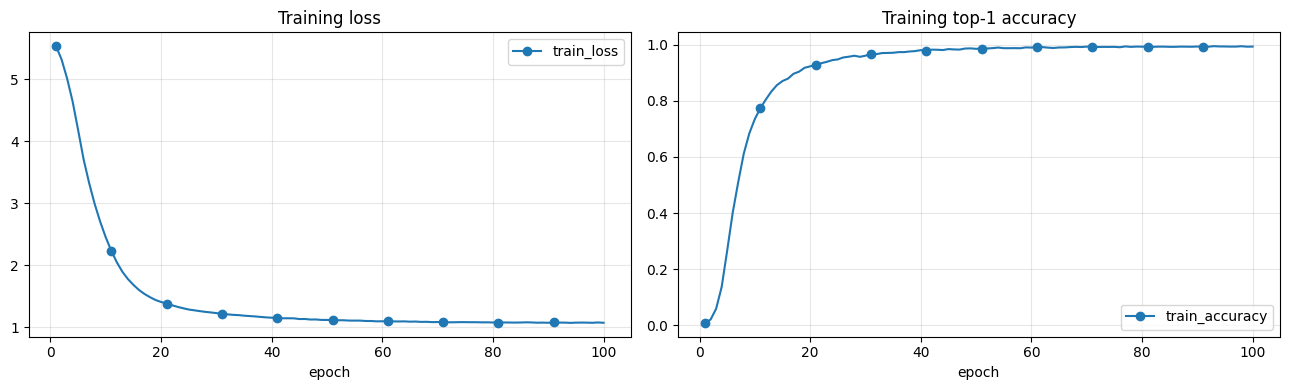

,epoch,train_loss,train_ce_loss,train_supcon_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,best_val_loss,best_epoch,bad_epochs,backbone_trainable,backbone_lr,head_lr,fusion_mode
95,96,1.073492,1.021592,1.038003,0.993983,0.993878,0.986204,0.994872,0.994558,0.98607,93,3,True,1.126671e-07,5.363597e-07,query_plus_gated_topk_context
96,97,1.072191,1.020434,1.035157,0.994106,0.994064,0.986241,0.994872,0.994558,0.98607,93,4,True,1.071298e-07,3.456090e-07,query_plus_gated_topk_context
97,98,1.069828,1.018362,1.029324,0.995334,0.995259,0.986176,0.994872,0.994558,0.98607,93,5,True,1.031702e-07,2.092093e-07,query_plus_gated_topk_context
98,99,1.075030,1.021874,1.063114,0.993738,0.993755,0.986138,0.994872,0.994558,0.98607,93,6,True,1.007928e-07,1.273098e-07,query_plus_gated_topk_context
99,100,1.070012,1.020477,0.990696,0.994106,0.994142,0.986120,0.994872,0.994558,0.98607,93,7,True,1.000000e-07,1.000000e-07,query_plus_gated_topk_context


In [9]:
if 'history_df' not in globals():
    history_df = pd.read_csv(OUT_PUT_DIR / 'training_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history_df.plot(x='epoch', y='train_loss', ax=axes[0], marker='o', markevery=max(1, len(history_df) // 10), title='Training loss')
history_df.plot(x='epoch', y='train_accuracy', ax=axes[1], marker='o', markevery=max(1, len(history_df) // 10), title='Training top-1 accuracy')
for axis in axes:
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
display(history_df.tail())


## 7. Official test accuracy

Cell này load final checkpoint; nếu final chưa có vì training bị dừng giữa chừng thì dùng `checkpoint_last.pt`. Metric chính là `test_accuracy`, tương ứng hàng **Random Context Ret.** cho Cars trong Table 2.


## 8. Inference và load checkpoint

Dùng hàm này để test nhanh một ảnh. Nếu không truyền context thủ công, hàm sẽ chọn context ngẫu nhiên từ candidate pool bằng seed cố định.


In [10]:
def macro_f1_score_np(y_true, y_pred, num_classes):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    f1_values = []
    for class_id in range(num_classes):
        tp = np.sum((y_true == class_id) & (y_pred == class_id))
        fp = np.sum((y_true != class_id) & (y_pred == class_id))
        fn = np.sum((y_true == class_id) & (y_pred != class_id))
        denom = 2 * tp + fp + fn
        f1_values.append(0.0 if denom == 0 else (2 * tp) / denom)
    return float(np.mean(f1_values))


@torch.no_grad()
def predict_logits_with_tta(
    network,
    query_images,
    context_images,
    context_scores,
    context_labels,
):
    logits_list = []

    logits = network(
        query_images,
        context_images,
        context_scores=context_scores,
    )
    logits = add_context_label_prior(logits, context_labels, context_scores)
    logits_list.append(logits)

    if globals().get("EVAL_TTA_HORIZONTAL_FLIP", True):
        logits = network(
            torch.flip(query_images, dims=[-1]),
            torch.flip(context_images, dims=[-1]),
            context_scores=context_scores,
        )
        logits = add_context_label_prior(logits, context_labels, context_scores)
        logits_list.append(logits)

    return torch.stack(logits_list, dim=0).mean(dim=0)


def evaluate_context_model(network, loader, top_k=TOP_K):
    network.eval()
    total_loss = 0.0
    all_targets, all_predictions, rows = [], [], []
    top_k = min(top_k, NUM_CLASSES)

    with torch.inference_mode():
        for batch in tqdm(loader, desc='test', leave=False):
            moved = move_batch_to_device(batch)
            logits = predict_logits_with_tta(
                network,
                moved["query_images"],
                moved["context_images"],
                moved["context_scores"],
                moved["context_labels"],
            )
            loss = criterion(logits, moved['labels'])
            probs = torch.softmax(logits, dim=1).cpu()
            values, indices = torch.topk(probs, k=top_k, dim=1)
            predictions = logits.argmax(dim=1).detach().cpu()
            labels_cpu = moved['labels'].detach().cpu()
            context_labels_cpu = batch['context_labels'].cpu()
            context_scores_cpu = batch['context_scores'].cpu()

            total_loss += loss.item() * moved['query_images'].size(0)
            all_targets.extend(labels_cpu.tolist())
            all_predictions.extend(predictions.tolist())

            for row_index, (fname, ctx_fnames, label, pred, value_row, index_row) in enumerate(
                zip(batch['fname'], batch['context_fnames'], labels_cpu, predictions, values, indices)
            ):
                label_id = int(label)
                pred_id = int(pred)
                context_label_ids = [int(x) for x in context_labels_cpu[row_index].tolist()]
                context_score_values = [float(x) for x in context_scores_cpu[row_index].tolist()]
                top_class_ids = [int(index) for index in index_row]
                rows.append({
                    'fname': fname,
                    'true_class_id': label_id,
                    'true_car_name': class_names[label_id],
                    'context_fnames': ctx_fnames,
                    'context_class_ids': '|'.join(str(x) for x in context_label_ids),
                    'context_car_names': '|'.join(class_names[x] for x in context_label_ids),
                    'random_scores': '|'.join(f'{x:.6f}' for x in context_score_values),
                    'top1_context_fname': str(ctx_fnames).split('|')[0],
                    'top1_context_class_id': context_label_ids[0],
                    'top1_context_car_name': class_names[context_label_ids[0]],
                    'top1_random_score': context_score_values[0],
                    'same_class_context_top1': bool(label_id == context_label_ids[0]),
                    'same_class_context_any_topk': bool(label_id in context_label_ids),
                    'same_class_context': bool(label_id in context_label_ids),
                    'predicted_class_id': pred_id,
                    'predicted_car_name': class_names[pred_id],
                    'correct': bool(pred_id == label_id),
                    'confidence': float(value_row[0]),
                    'top_k_class_ids': '|'.join(str(index) for index in top_class_ids),
                    'top_k_car_names': '|'.join(class_names[index] for index in top_class_ids),
                    'top_k_probabilities': '|'.join(f'{float(value):.6f}' for value in value_row),
                })

    y_true = np.asarray(all_targets)
    y_pred = np.asarray(all_predictions)
    return {
        'test_loss': total_loss / len(loader.dataset),
        'test_accuracy': float(np.mean(y_true == y_pred)),
        'test_macro_f1': macro_f1_score_np(y_true, y_pred, NUM_CLASSES),
        'predictions': pd.DataFrame(rows),
    }


evaluation_checkpoint_path = best_checkpoint_path if best_checkpoint_path.is_file() else (
    checkpoint_path if checkpoint_path.is_file() else last_checkpoint_path
)
saved_checkpoint = torch.load(evaluation_checkpoint_path, map_location=DEVICE)
model.load_state_dict(saved_checkpoint['model_state_dict'])
model.eval()
print('Loaded checkpoint for evaluation:', evaluation_checkpoint_path.resolve())

results = evaluate_context_model(model, test_loader, top_k=TOP_K)
test_prediction_df = results.pop('predictions')
test_prediction_df.to_csv(OUT_PUT_DIR / 'test_predictions.csv', index=False)

metrics = {
    'method': 'Random Context Ret. - fixed random candidate pool',
    'test_accuracy': results['test_accuracy'],
    'test_loss': results['test_loss'],
    'test_macro_f1': results['test_macro_f1'],
    'num_classes': NUM_CLASSES,
    'standard_train_size': len(full_train_df),
    'train_size': len(train_dataset),
    'val_size': len(val_dataset),
    'standard_test_size': len(test_dataset),
    'architecture': BACKBONE_NAME,
    'pretraining': 'DINOv3',
    'retriever': 'fixed random context sampled from candidate pool; no DINO similarity ranking',
    'fusion_mode': getattr(model, 'active_fusion_mode', saved_checkpoint.get('fusion_mode', 'unknown')),
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'seed': SEED,
    'use_bbox_crop': USE_BBOX_CROP,
    'val_fraction': VAL_FRACTION,
    'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
    'candidate_pool_size': len(candidate_df),
    'context_top_k': CONTEXT_TOP_K,
    'retrieval_score_weight': RETRIEVAL_SCORE_WEIGHT,
    'supcon_weight': SUPCON_WEIGHT,
    'use_context_label_prior': USE_CONTEXT_LABEL_PRIOR,
    'test_context_top1_same_class_rate': float(test_prediction_df['same_class_context_top1'].mean()),
    'test_context_same_class_rate': float(test_prediction_df['same_class_context_any_topk'].mean()),
    'test_mean_top1_random_score': float(test_prediction_df['top1_random_score'].mean()),
    'checkpoint': str(evaluation_checkpoint_path),
    'checkpoint_selection': 'best_val_if_available',
}

with open(OUT_PUT_DIR / 'metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, ensure_ascii=False, indent=2)

print(f"test_accuracy: {metrics['test_accuracy']:.4f} ({metrics['test_accuracy'] * 100:.2f}%)")
print(f"test_loss: {metrics['test_loss']:.4f}")
print(f"test_macro_f1: {metrics['test_macro_f1']:.4f}")
print(f"top1_same_class_random_context_rate: {metrics['test_context_top1_same_class_rate']:.4f}")
print(f"any_top{CONTEXT_TOP_K}_same_class_random_context_rate: {metrics['test_context_same_class_rate']:.4f}")
print('Saved test predictions:', (OUT_PUT_DIR / 'test_predictions.csv').resolve())
print('Saved metrics:', (OUT_PUT_DIR / 'metrics.json').resolve())
display(test_prediction_df.head())


Loaded checkpoint for evaluation: /kaggle/working/outputs/baseline_random_context_ret_cars/best_val_checkpoint.pt


test:   0%|          | 0/126 [00:00<?, ?it/s]

/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_163/3916629466.py:74: UserWarning: To copy construct from a tensor, it is recommen

test_accuracy: 0.9438 (94.38%)
test_loss: 1.1442
test_macro_f1: 0.9429
top1_same_class_random_context_rate: 0.0052
any_top1_same_class_random_context_rate: 0.0052
Saved test predictions: /kaggle/working/outputs/baseline_random_context_ret_cars/test_predictions.csv
Saved metrics: /kaggle/working/outputs/baseline_random_context_ret_cars/metrics.json


,fname,true_class_id,true_car_name,context_fnames,context_class_ids,context_car_names,random_scores,top1_context_fname,top1_context_class_id,top1_context_car_name,...,same_class_context_top1,same_class_context_any_topk,same_class_context,predicted_class_id,predicted_car_name,correct,confidence,top_k_class_ids,top_k_car_names,top_k_probabilities
0,00001.jpg,180,Suzuki Aerio Sedan 2007,02435.jpg,174,Rolls-Royce Phantom Drophead Coupe Convertible...,0.000000,02435.jpg,174,Rolls-Royce Phantom Drophead Coupe Convertible...,...,False,False,False,180,Suzuki Aerio Sedan 2007,True,0.930011,180|187|164|114|141,Suzuki Aerio Sedan 2007|Toyota Corolla Sedan 2...,0.930011|0.006015|0.003586|0.003029|0.002224
1,00002.jpg,102,Ferrari 458 Italia Convertible 2012,05287.jpg,151,Lamborghini Gallardo LP 570-4 Superleggera 2012,0.000000,05287.jpg,151,Lamborghini Gallardo LP 570-4 Superleggera 2012,...,False,False,False,102,Ferrari 458 Italia Convertible 2012,True,0.919626,102|101|103|95|134,Ferrari 458 Italia Convertible 2012|Ferrari Ca...,0.919626|0.013373|0.010044|0.003267|0.003219
2,00003.jpg,144,Jeep Patriot SUV 2012,00764.jpg,164,Mercedes-Benz S-Class Sedan 2012,0.000000,00764.jpg,164,Mercedes-Benz S-Class Sedan 2012,...,False,False,False,144,Jeep Patriot SUV 2012,True,0.927621,144|146|153|123|69,Jeep Patriot SUV 2012|Jeep Liberty SUV 2012|La...,0.927621|0.007081|0.006094|0.002625|0.002540
3,00004.jpg,186,Toyota Camry Sedan 2012,03304.jpg,62,Chevrolet Sonic Sedan 2012,0.000000,03304.jpg,62,Chevrolet Sonic Sedan 2012,...,False,False,False,186,Toyota Camry Sedan 2012,True,0.904497,186|187|4|139|103,Toyota Camry Sedan 2012|Toyota Corolla Sedan 2...,0.904497|0.009854|0.007617|0.004493|0.003983
4,00005.jpg,184,Tesla Model S Sedan 2012,06061.jpg,1,Acura RL Sedan 2012,0.000000,06061.jpg,1,Acura RL Sedan 2012,...,False,False,False,184,Tesla Model S Sedan 2012,True,0.950773,184|172|193|104|164,Tesla Model S Sedan 2012|Porsche Panamera Seda...,0.950773|0.002076|0.002007|0.001834|0.001212


In [11]:
def find_random_contexts_for_image(image_path=None, top_k=CONTEXT_TOP_K, seed=None):
    rng = np.random.default_rng(SEED if seed is None else seed)
    top_k = int(max(1, min(top_k, len(candidate_df))))
    positions = rng.choice(len(candidate_df), size=top_k, replace=len(candidate_df) < top_k)
    context_rows = [candidate_df.iloc[int(pos)] for pos in positions]
    return context_rows, [0.0 for _ in context_rows]


def predict_one_image_with_random_context(image_path, context_image_paths=None, network=model, top_k=TOP_K):
    image_path = Path(image_path)
    if context_image_paths is None:
        context_rows, context_scores = find_random_contexts_for_image(image_path, top_k=CONTEXT_TOP_K)
        context_image_paths = [Path(row['image_path']) for row in context_rows]
        context_names = [class_names[int(row['class_id'])] for row in context_rows]
        context_labels = [int(row['class_id']) for row in context_rows]
    else:
        if isinstance(context_image_paths, (str, Path)):
            context_image_paths = [context_image_paths]
        context_image_paths = [Path(path) for path in context_image_paths]
        context_names = [None] * len(context_image_paths)
        context_labels = [0] * len(context_image_paths)
        context_scores = [0.0] * len(context_image_paths)

    query_image = eval_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(DEVICE)
    context_images = torch.stack([
        eval_transform(Image.open(path).convert('RGB')) for path in context_image_paths
    ], dim=0).unsqueeze(0).to(DEVICE)
    context_scores_tensor = torch.tensor([context_scores], dtype=torch.float32, device=DEVICE)
    context_labels_tensor = torch.tensor([context_labels], dtype=torch.long, device=DEVICE)

    network.eval()
    with torch.inference_mode():
        logits = network(query_image, context_images, context_scores=context_scores_tensor)
        logits = add_context_label_prior(logits, context_labels_tensor, context_scores_tensor)
        probs = torch.softmax(logits, dim=1)[0]
        values, indices = torch.topk(probs, k=min(top_k, NUM_CLASSES))

    print('Query:', image_path)
    for rank, (context_path, context_name, score) in enumerate(zip(context_image_paths, context_names, context_scores), start=1):
        print(f'Random context {rank}:', context_path)
        if context_name is not None:
            print(f'  label: {context_name}')
        print(f'  random score: {score:.4f}')
    print('\nTop predictions:')
    for rank, (class_id, probability) in enumerate(zip(indices.tolist(), values.tolist()), start=1):
        print(f'{rank}. {class_names[class_id]} | p={probability:.4f}')


def load_random_context_model_for_inference(checkpoint_file, device=DEVICE):
    saved = torch.load(checkpoint_file, map_location=device)
    loaded_model = DinoV3GatedTopKContextClassifier(
        repo_dir=DINOV3_REPO_DIR,
        model_name=DINOV3_MODEL_NAME,
        weights_path=resolve_dinov3_weights(),
        num_classes=len(saved['class_names']),
        feature_dim=FEATURE_DIM,
        allow_feature_fallback=False,
    )
    loaded_model.load_state_dict(saved['model_state_dict'])
    return loaded_model.to(device).eval(), saved['class_names']


print('Final checkpoint:', checkpoint_path.resolve())
print('Best-val checkpoint:', best_checkpoint_path.resolve())
print('Latest checkpoint:', last_checkpoint_path.resolve())
print('Method:', 'Random Context Ret. - fixed random candidate pool')


Final checkpoint: /kaggle/working/outputs/baseline_random_context_ret_cars/final_random_context_ret_dinov3_vits16_cars.pt
Best-val checkpoint: /kaggle/working/outputs/baseline_random_context_ret_cars/best_val_checkpoint.pt
Latest checkpoint: /kaggle/working/outputs/baseline_random_context_ret_cars/checkpoint_last.pt
Method: Random Context Ret. - fixed random candidate pool


In [12]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

## 9. Ghi chú benchmark

- Method này là bản **Random Context Ret.** dựa trên hàng thứ 2 của Table 2: context được chọn ngẫu nhiên, không dùng DINO similarity để retrieval và không học selector.
- Candidate pool mặc định lấy **20% train split**, đúng phần Candidate Pool Construction trong paper.
- `CONTEXT_TOP_K = 1` để gần nhất với mô tả “a random candidate is paired with each query”.
- Notebook vẫn giữ các phần làm bản trước ổn định/điểm cao: DINOv3 ViT-S/16, token-level fusion, gated query/context head, strong augmentation, checkpoint sau từng epoch và TTA.
- `USE_CONTEXT_LABEL_PRIOR=False` vì context-label prior không có trong paper và sẽ làm benchmark Random Context Ret. không còn trung thực.
- `USE_BBOX_CROP=True`, `IMAGE_SIZE=448`, strong augmentation và gated head là các lựa chọn thực nghiệm giúp tăng điểm; nếu cần paper-faithful tuyệt đối hơn, hãy đổi `IMAGE_SIZE=256`, tắt bbox crop nếu paper không nêu, và dùng 3 seeds.
- Metric chính cho Cars là `test_accuracy`; nên theo dõi thêm `top1_same_class_random_context_rate`, giá trị này với random context thường rất thấp vì có 196 lớp.
- Những file nên giữ để so sánh method: `metrics.json`, `training_history.csv`, `test_predictions.csv`, `candidate_pool.csv`, `train_random_context_pairs.csv`, `test_random_context_pairs.csv`, `random_context_retrieval_cache.pt`, `checkpoint_last.pt`, `best_val_checkpoint.pt`, và final checkpoint.


In [ ]:

# --- CELL CUỐI: TỰ ĐỘNG DỪNG TÍNH TOÁN & SHUTDOWN PHIÊN ---
import os
import time
import torch

print("=== QUÁ TRÌNH HUẤN LUYỆN VÀ ĐÁNH GIÁ ĐÃ HOÀN TẤT ===")

# 1. Giải phóng toàn bộ VRAM
if torch.cuda.is_available():
    torch.cuda.empty_cache()

time.sleep(2)

# 2. Tắt Kernel để dừng ngay lập tức mọi tác vụ đang chạy
try:
    from ipykernel.kernelapp import IPKernelApp
    IPKernelApp.instance().shutdown()
except Exception:
    os._exit(0)

=== QUÁ TRÌNH HUẤN LUYỆN VÀ ĐÁNH GIÁ ĐÃ HOÀN TẤT ===


In [ ]:
# import numpy as np
# import pandas as pd
# from PIL import Image
# from tqdm import tqdm

# def analyze_dataset_dimensions(df, check_bbox=True):
#     widths, heights = [], []
#     crop_w_list, crop_h_list = [], []

#     for _, row in tqdm(df.iterrows(), total=len(df), desc="Đang quét kích thước ảnh"):
#         # Image.open chỉ đọc metadata header, cực nhanh và không tốn RAM
#         with Image.open(row['image_path']) as img:
#             w, h = img.size
#             widths.append(w)
#             heights.append(h)

#         if check_bbox and 'bbox_x1' in row:
#             left = max(0, int(row['bbox_x1']) - 1)
#             top = max(0, int(row['bbox_y1']) - 1)
#             right = max(left + 1, int(row['bbox_x2']))
#             bottom = max(top + 1, int(row['bbox_y2']))
#             crop_w_list.append(right - left)
#             crop_h_list.append(bottom - top)

#     data = {
#         "Metric": ["Min", "Max", "Mean", "Median"],
#         "Orig Width (W)": [np.min(widths), np.max(widths), round(np.mean(widths), 1), np.median(widths)],
#         "Orig Height (H)": [np.min(heights), np.max(heights), round(np.mean(heights), 1), np.median(heights)],
#     }

#     if check_bbox and crop_w_list:
#         data["Crop Width (BBox)"] = [np.min(crop_w_list), np.max(crop_w_list), round(np.mean(crop_w_list), 1), np.median(crop_w_list)]
#         data["Crop Height (BBox)"] = [np.min(crop_h_list), np.max(crop_h_list), round(np.mean(crop_h_list), 1), np.median(crop_h_list)]

#     stats_df = pd.DataFrame(data)
    
#     # Tính tỉ lệ khung hình (Aspect Ratio W/H)
#     aspect_ratios = np.array(widths) / np.array(heights)
#     print(f"Aspect ratio gốc trung bình (W/H): {aspect_ratios.mean():.2f}")
#     print(f"Số ảnh có W > H (ảnh ngang): {np.sum(aspect_ratios > 1.0)} / {len(df)} ({np.mean(aspect_ratios > 1.0):.1%})")
    
#     return stats_df

# # Kiểm tra trên tập train
# train_size_stats = analyze_dataset_dimensions(full_train_df, check_bbox=USE_BBOX_CROP)
# display(train_size_stats)